Model Training & Comparison

1. Set up and Load Data

In [2]:
import os
import numpy as np
import pandas as pd
import joblib
import time
import warnings
warnings.filterwarnings('ignore')

BASE_DIR       = os.path.abspath(os.path.join(os.getcwd(), '..'))
FEATURES_DIR   = os.path.join(BASE_DIR, 'Data', 'Features')
MODELS_DIR     = os.path.join(BASE_DIR, 'Models')
TRAIN_TEST_DIR = os.path.join(MODELS_DIR, 'Train_Test')

for d in [
    os.path.join(TRAIN_TEST_DIR, 'dataset1'),
    os.path.join(TRAIN_TEST_DIR, 'dataset2'),
    os.path.join(MODELS_DIR, 'dataset1'),
    os.path.join(MODELS_DIR, 'dataset2'),
]:
    os.makedirs(d, exist_ok=True)

print(f"FEATURES_DIR   : {FEATURES_DIR}")
print(f"MODELS_DIR     : {MODELS_DIR}")
print(f"TRAIN_TEST_DIR : {TRAIN_TEST_DIR}")
print(f"\nAll dirs created: ")

FEATURES_DIR   : d:\Study Assets\Final Project\PhishingGuard\Data\Features
MODELS_DIR     : d:\Study Assets\Final Project\PhishingGuard\Models
TRAIN_TEST_DIR : d:\Study Assets\Final Project\PhishingGuard\Models\Train_Test

All dirs created: 


2. Load & Define Feature Columns

In [3]:
df1 = pd.read_csv(os.path.join(FEATURES_DIR, 'dataset1_features.csv'))
df2 = pd.read_csv(os.path.join(FEATURES_DIR, 'dataset2_features.csv'))

print("── Loaded ──")
print(f"  Dataset 1 : {df1.shape} | Label: {sorted(df1['Label'].unique())}")
print(f"  Dataset 2 : {df2.shape} | Label: {sorted(df2['Label'].unique())}")

FEATURE_COLS = [c for c in df1.columns if c not in ['URL', 'Label']]
print(f"\nFeature columns ({len(FEATURE_COLS)}): {FEATURE_COLS}")

── Loaded ──
  Dataset 1 : (509743, 34) | Label: ['benign', 'defacement', 'malware', 'phishing']
  Dataset 2 : (103820, 34) | Label: [np.int64(0), np.int64(1)]

Feature columns (32): ['url_length', 'domain_length', 'path_length', 'num_dots', 'num_hyphens', 'num_underscores', 'num_slashes', 'num_at', 'num_question_marks', 'num_equals', 'num_ampersands', 'num_percent', 'num_digits', 'digit_ratio', 'letter_ratio', 'url_entropy', 'domain_entropy', 'num_subdomains', 'has_ip_address', 'has_https', 'is_suspicious_tld', 'has_port', 'path_depth', 'num_query_params', 'has_fragment', 'is_shortened_url', 'has_suspicious_word', 'consonant_ratio', 'vowel_ratio', 'longest_token_length', 'avg_token_length', 'special_char_ratio']


3. Train/Val Split (80/20) + Save

In [4]:
from sklearn.model_selection import train_test_split

def split_and_save(df, label_col, dataset_name):
    train, val = train_test_split(
        df,
        test_size=0.2,
        random_state=42,
        stratify=df[label_col]
    )
    train = train.reset_index(drop=True)
    val   = val.reset_index(drop=True)

    out_dir = os.path.join(TRAIN_TEST_DIR, dataset_name)
    train_path = os.path.join(out_dir, 'train.csv')
    val_path   = os.path.join(out_dir, 'val.csv')

    train.to_csv(train_path, index=False)
    val.to_csv(val_path, index=False)

    print(f"\n[{dataset_name}]")
    print(f"  Train : {len(train):,} rows → {os.path.basename(train_path)}")
    print(f"  Val   : {len(val):,} rows → {os.path.basename(val_path)}")
    print(f"  Train label dist: {train[label_col].value_counts(normalize=True).round(3).to_dict()}")
    print(f"  Val   label dist: {val[label_col].value_counts(normalize=True).round(3).to_dict()}")

    return train, val

print("── Train/Val Split (80/20, stratified) ──")
train1, val1 = split_and_save(df1, 'Label', 'dataset1')
train2, val2 = split_and_save(df2, 'Label', 'dataset2')

print("\n Đã lưu train/val cho cả 2 dataset")

── Train/Val Split (80/20, stratified) ──

[dataset1]
  Train : 407,794 rows → train.csv
  Val   : 101,949 rows → val.csv
  Train label dist: {'benign': 0.666, 'defacement': 0.15, 'phishing': 0.148, 'malware': 0.037}
  Val   label dist: {'benign': 0.666, 'defacement': 0.15, 'phishing': 0.148, 'malware': 0.037}

[dataset2]
  Train : 83,056 rows → train.csv
  Val   : 20,764 rows → val.csv
  Train label dist: {0: 0.578, 1: 0.422}
  Val   label dist: {0: 0.578, 1: 0.422}

 Đã lưu train/val cho cả 2 dataset


4. Prepare X, y + Feature Scaling

In [5]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

# ── Dataset 1 — multi-class, cần encode label ──
le1 = LabelEncoder()
X_train1 = train1[FEATURE_COLS].values
y_train1 = le1.fit_transform(train1['Label'])
X_val1   = val1[FEATURE_COLS].values
y_val1   = le1.transform(val1['Label'])
LABEL_NAMES_1 = list(le1.classes_)
print(f"Dataset 1 label mapping: {dict(zip(le1.classes_, le1.transform(le1.classes_)))}")

# ── Dataset 2 — binary, label đã là 0/1 ──
X_train2 = train2[FEATURE_COLS].values
y_train2 = train2['Label'].values
X_val2   = val2[FEATURE_COLS].values
y_val2   = val2['Label'].values

# ── Scaled version — dùng cho kNN, Logistic Regression, SVM ──
scaler1 = StandardScaler().fit(X_train1)
X_train1_scaled = scaler1.transform(X_train1)
X_val1_scaled   = scaler1.transform(X_val1)

scaler2 = StandardScaler().fit(X_train2)
X_train2_scaled = scaler2.transform(X_train2)
X_val2_scaled   = scaler2.transform(X_val2)

# Lưu scaler ra .pkl — cần thiết cho explainability.ipynb transform lại đúng cùng tham số
joblib.dump(scaler1, os.path.join(MODELS_DIR, 'dataset1', 'scaler1.pkl'))
joblib.dump(scaler2, os.path.join(MODELS_DIR, 'dataset2', 'scaler2.pkl'))

print(f"\nX_train1: {X_train1.shape} | X_train2: {X_train2.shape}")
print(" Scaled arrays ready cho kNN / Logistic Regression / SVM")
print(" Raw arrays (X_train1, X_train2) dùng cho Decision Tree / RF / XGBoost")

Dataset 1 label mapping: {'benign': np.int64(0), 'defacement': np.int64(1), 'malware': np.int64(2), 'phishing': np.int64(3)}

X_train1: (407794, 32) | X_train2: (83056, 32)
 Scaled arrays ready cho kNN / Logistic Regression / SVM
 Raw arrays (X_train1, X_train2) dùng cho Decision Tree / RF / XGBoost


5. Shared Training & Evaluation Function

In [6]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

all_results = {}  # lưu kết quả tất cả model × dataset

IMAGES_DIR = os.path.join(BASE_DIR, 'Reports', 'Images', 'confusion_matrix')
os.makedirs(IMAGES_DIR, exist_ok=True)

def plot_confusion_heatmap(cm, label_names, model_key, dataset_name, accuracy):
    labels = label_names if label_names else ['0', '1']
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='rocket',
                xticklabels=labels, yticklabels=labels, cbar=True)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'{model_key} — {dataset_name}\nAccuracy: {accuracy:.4f}')
    plt.tight_layout()

    save_path = os.path.join(IMAGES_DIR, f'{dataset_name}_{model_key}.png')
    plt.savefig(save_path, dpi=150)
    plt.show()
    plt.close()

def train_evaluate_save(model, model_key, dataset_name,
                          X_train, y_train, X_val, y_val,
                          label_names=None):
    print(f"\n  ── {dataset_name} ──")
    t0 = time.time()
    model.fit(X_train, y_train)
    elapsed = round(time.time() - t0, 1)

    y_pred = model.predict(X_val)
    acc = accuracy_score(y_val, y_pred)
    cm  = confusion_matrix(y_val, y_pred)
    report = classification_report(y_val, y_pred, target_names=label_names,
                                     zero_division=0)

    print(f"  Train time : {elapsed}s")
    print(f"  Accuracy   : {acc:.4f}")
    print(f"  Confusion Matrix:\n{cm}")
    print(f"\n  Classification Report:\n{report}")

    # ── Heatmap hiển thị ngay cùng output, đồng thời lưu vào Reports/Images/confusion_matrix/ ──
    plot_confusion_heatmap(cm, label_names, model_key, dataset_name, acc)

    save_dir  = os.path.join(MODELS_DIR, dataset_name)
    save_path = os.path.join(save_dir, f"{model_key}.pkl")
    joblib.dump(model, save_path)
    print(f"  Saved → {dataset_name}/{model_key}.pkl")

    all_results[f"{dataset_name}_{model_key}"] = {
        'dataset': dataset_name, 'model': model_key,
        'accuracy': round(acc, 4), 'train_time': elapsed
    }
    return model

print(" Shared functions ready (kèm auto-plot confusion matrix heatmap)")


 Shared functions ready (kèm auto-plot confusion matrix heatmap)


6. KNN 

- Dataset 1

══ MODEL: kNN — Dataset 1 ══

  ── dataset1 ──
  Train time : 0.1s
  Accuracy   : 0.9038
  Confusion Matrix:
[[64445  1538    48  1831]
 [ 1603 13177     5   464]
 [  230    31  3334   188]
 [ 2872   913    85 11185]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.93      0.95      0.94     67862
  defacement       0.84      0.86      0.85     15249
     malware       0.96      0.88      0.92      3783
    phishing       0.82      0.74      0.78     15055

    accuracy                           0.90    101949
   macro avg       0.89      0.86      0.87    101949
weighted avg       0.90      0.90      0.90    101949



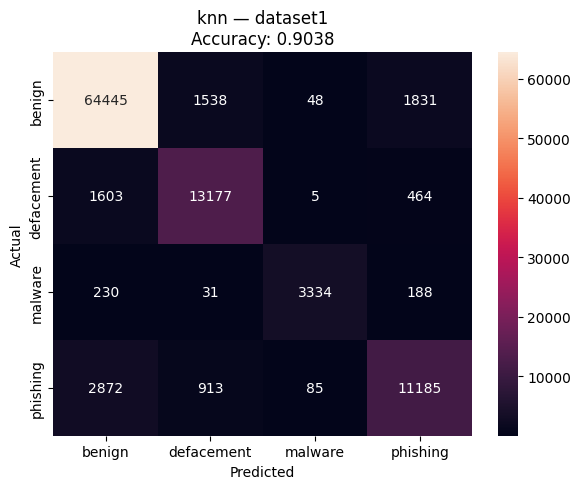

  Saved → dataset1/knn.pkl


,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",-1
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](4,)","[0,1,2,3]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [7]:
from sklearn.neighbors import KNeighborsClassifier

print("══ MODEL: kNN — Dataset 1 ══")

knn1 = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
train_evaluate_save(knn1, 'knn', 'dataset1',
                     X_train1_scaled, y_train1, X_val1_scaled, y_val1,
                     label_names=LABEL_NAMES_1)

- Dataset 2

══ MODEL: kNN — Dataset 2 ══

  ── dataset2 ──
  Train time : 0.0s
  Accuracy   : 0.9492
  Confusion Matrix:
[[11575   420]
 [  635  8134]]

  Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.96     11995
           1       0.95      0.93      0.94      8769

    accuracy                           0.95     20764
   macro avg       0.95      0.95      0.95     20764
weighted avg       0.95      0.95      0.95     20764



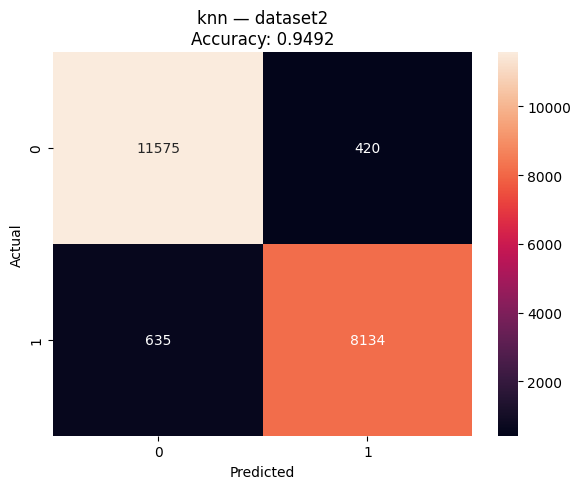

  Saved → dataset2/knn.pkl


,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",-1
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [8]:
print("══ MODEL: kNN — Dataset 2 ══")

knn2 = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
train_evaluate_save(knn2, 'knn', 'dataset2',
                     X_train2_scaled, y_train2, X_val2_scaled, y_val2)

7. Logistic Regression

-  Dataset 1 (class_weight = 'balanced')

══ MODEL: Logistic Regression — Dataset 1 ══

  ── dataset1 ──
  Train time : 13.1s
  Accuracy   : 0.6772
  Confusion Matrix:
[[43826  6990  1306 15740]
 [ 1785 11540    15  1909]
 [  279   155  3105   244]
 [ 2569  1155   762 10569]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.90      0.65      0.75     67862
  defacement       0.58      0.76      0.66     15249
     malware       0.60      0.82      0.69      3783
    phishing       0.37      0.70      0.49     15055

    accuracy                           0.68    101949
   macro avg       0.61      0.73      0.65    101949
weighted avg       0.77      0.68      0.70    101949



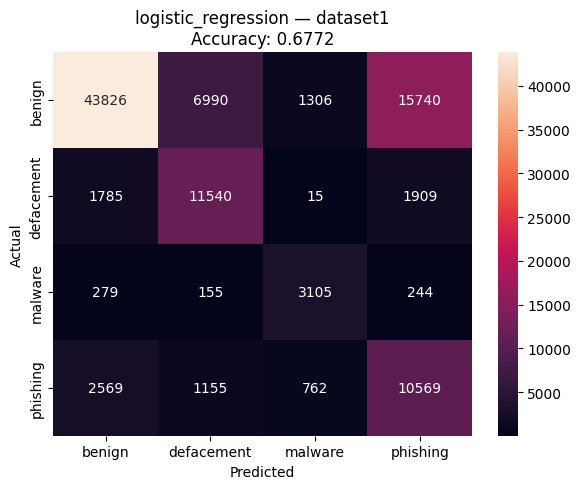

  Saved → dataset1/logistic_regression.pkl


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"n_jobs n_jobs: int, default=NoneDoes not have any effect... deprecated:: 1.8 `n_jobs` is deprecated in version 1.8 and will be removed in 1.10.",-1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1


In [9]:
from sklearn.linear_model import LogisticRegression

print("══ MODEL: Logistic Regression — Dataset 1 ══")

lr1 = LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1, class_weight='balanced')
train_evaluate_save(lr1, 'logistic_regression', 'dataset1',
                     X_train1_scaled, y_train1, X_val1_scaled, y_val1,
                     label_names=LABEL_NAMES_1)

- Dataset 1 (custom manual)

══ MODEL: Logistic Regression — Dataset 1 (custom manual) ══

  ── dataset1 ──
  Train time : 12.3s
  Accuracy   : 0.7694
  Confusion Matrix:
[[57049  2929   211  7673]
 [ 3797  9756     0  1696]
 [  514   118  2896   255]
 [ 5304   669   348  8734]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.86      0.84      0.85     67862
  defacement       0.72      0.64      0.68     15249
     malware       0.84      0.77      0.80      3783
    phishing       0.48      0.58      0.52     15055

    accuracy                           0.77    101949
   macro avg       0.72      0.71      0.71    101949
weighted avg       0.78      0.77      0.77    101949



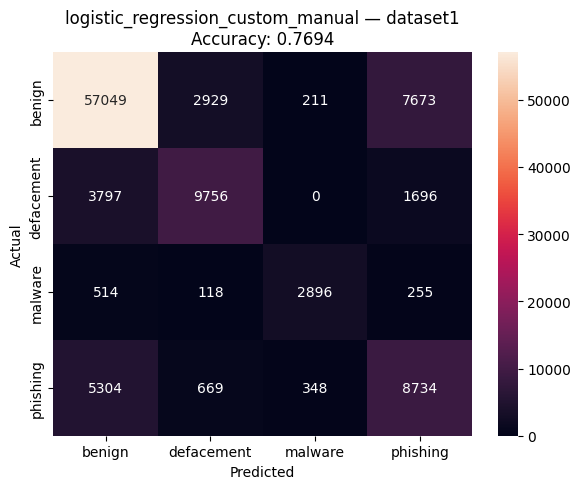

  Saved → dataset1/logistic_regression_custom_manual.pkl


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*","{0: 1, 1: 2, 2: 4, 3: 2.5}"
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"n_jobs n_jobs: int, default=NoneDoes not have any effect... deprecated:: 1.8 `n_jobs` is deprecated in version 1.8 and will be removed in 1.10.",-1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be inc

In [10]:
print("══ MODEL: Logistic Regression — Dataset 1 (custom manual) ══")

custom_manual = {0: 1, 1: 2, 2: 4, 3: 2.5}

lr1_custom = LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1, class_weight=custom_manual)
train_evaluate_save(lr1_custom, 'logistic_regression_custom_manual', 'dataset1',
                     X_train1_scaled, y_train1, X_val1_scaled, y_val1,
                     label_names=LABEL_NAMES_1)

- Dataset 2

══ MODEL: Logistic Regression — Dataset 2 ══

  ── dataset2 ──
  Train time : 0.4s
  Accuracy   : 0.8538
  Confusion Matrix:
[[10295  1700]
 [ 1336  7433]]

  Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.86      0.87     11995
           1       0.81      0.85      0.83      8769

    accuracy                           0.85     20764
   macro avg       0.85      0.85      0.85     20764
weighted avg       0.86      0.85      0.85     20764



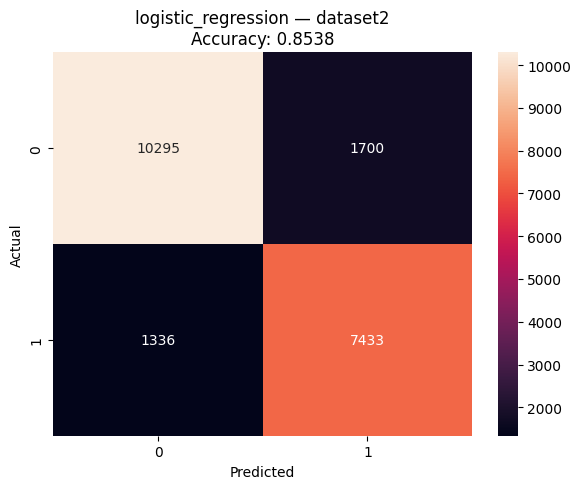

  Saved → dataset2/logistic_regression.pkl


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"n_jobs n_jobs: int, default=NoneDoes not have any effect... deprecated:: 1.8 `n_jobs` is deprecated in version 1.8 and will be removed in 1.10.",-1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1


In [11]:
print("══ MODEL: Logistic Regression — Dataset 2 ══")

lr2 = LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1, class_weight= 'balanced')
train_evaluate_save(lr2, 'logistic_regression', 'dataset2',
                     X_train2_scaled, y_train2, X_val2_scaled, y_val2)

8. Decision Tree

- Dataset 1

══ MODEL: Decision Tree — Dataset 1 ══

  ── dataset1 ──
  Train time : 6.6s
  Accuracy   : 0.8794
  Confusion Matrix:
[[64527  1328    24  1983]
 [ 2910 11513     3   823]
 [  379    44  3155   205]
 [ 3614   859   118 10464]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.90      0.95      0.93     67862
  defacement       0.84      0.76      0.79     15249
     malware       0.96      0.83      0.89      3783
    phishing       0.78      0.70      0.73     15055

    accuracy                           0.88    101949
   macro avg       0.87      0.81      0.84    101949
weighted avg       0.88      0.88      0.88    101949



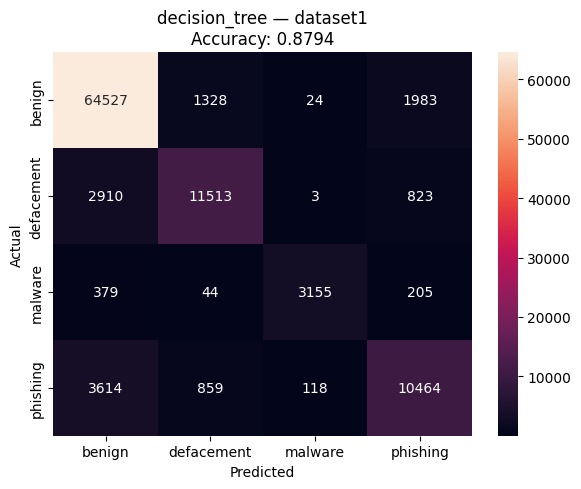

  Saved → dataset1/decision_tree.pkl


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at

In [12]:
from sklearn.tree import DecisionTreeClassifier

print("══ MODEL: Decision Tree — Dataset 1 ══")

dt1 = DecisionTreeClassifier(max_depth=15, random_state=42)
train_evaluate_save(dt1, 'decision_tree', 'dataset1',
                     X_train1, y_train1, X_val1, y_val1,
                     label_names=LABEL_NAMES_1)

- Dataset 2

══ MODEL: Decision Tree — Dataset 2 ══

  ── dataset2 ──
  Train time : 1.2s
  Accuracy   : 0.9436
  Confusion Matrix:
[[11501   494]
 [  678  8091]]

  Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.96      0.95     11995
           1       0.94      0.92      0.93      8769

    accuracy                           0.94     20764
   macro avg       0.94      0.94      0.94     20764
weighted avg       0.94      0.94      0.94     20764



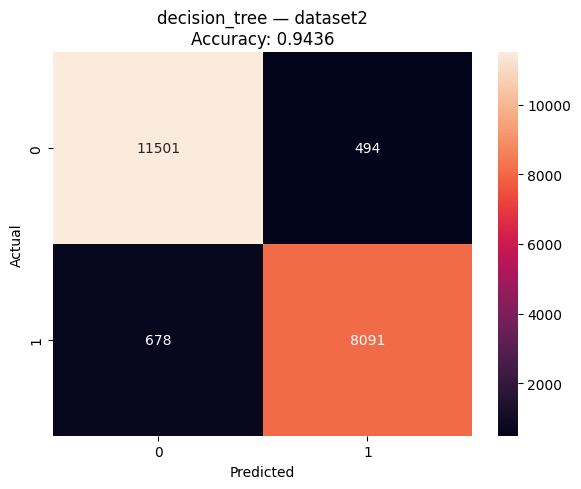

  Saved → dataset2/decision_tree.pkl


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at

In [13]:
print("══ MODEL: Decision Tree — Dataset 2 ══")

dt2 = DecisionTreeClassifier(max_depth=15, random_state=42)
train_evaluate_save(dt2, 'decision_tree', 'dataset2',
                     X_train2, y_train2, X_val2, y_val2)

9. SVM (LinearSVC)

- Dataset 1

══ MODEL: SVM (LinearSVC) — Dataset 1 ══

  ── dataset1 ──
  Train time : 107.3s
  Accuracy   : 0.7726
  Confusion Matrix:
[[59226  3186   292  5158]
 [ 4046  9783     0  1420]
 [  555   129  2922   177]
 [ 6543   966   707  6839]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.84      0.87      0.86     67862
  defacement       0.70      0.64      0.67     15249
     malware       0.75      0.77      0.76      3783
    phishing       0.50      0.45      0.48     15055

    accuracy                           0.77    101949
   macro avg       0.70      0.69      0.69    101949
weighted avg       0.77      0.77      0.77    101949



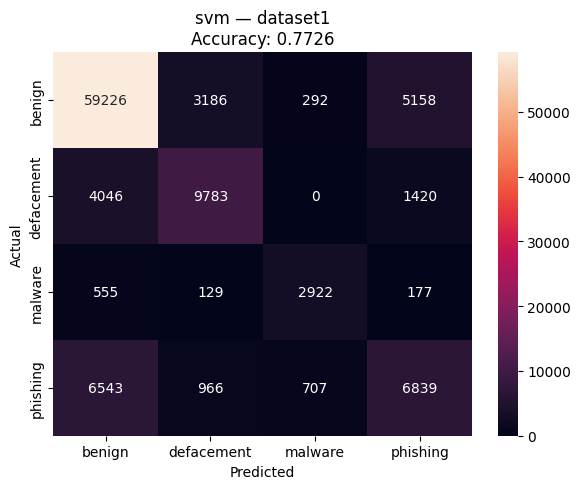

  Saved → dataset1/svm.pkl


,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forthe dual coordinate descent (if ``dual=True``). When ``dual=False`` theunderlying implementation of :class:`LinearSVC` is not random and``random_state`` has no effect on the results.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_iter max_iter: int, default=1000The maximum number of iterations to be run.",2000
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_

In [14]:
from sklearn.svm import LinearSVC

print("══ MODEL: SVM (LinearSVC) — Dataset 1 ══")

svm1 = LinearSVC(max_iter=2000, random_state=42, dual='auto', class_weight= 'balanced')
train_evaluate_save(svm1, 'svm', 'dataset1',
                     X_train1_scaled, y_train1, X_val1_scaled, y_val1,
                     label_names=LABEL_NAMES_1)

- Dataset 2


══ MODEL: SVM (LinearSVC) — Dataset 2 ══

  ── dataset2 ──
  Train time : 2.6s
  Accuracy   : 0.8468
  Confusion Matrix:
[[10158  1837]
 [ 1344  7425]]

  Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.85      0.86     11995
           1       0.80      0.85      0.82      8769

    accuracy                           0.85     20764
   macro avg       0.84      0.85      0.84     20764
weighted avg       0.85      0.85      0.85     20764



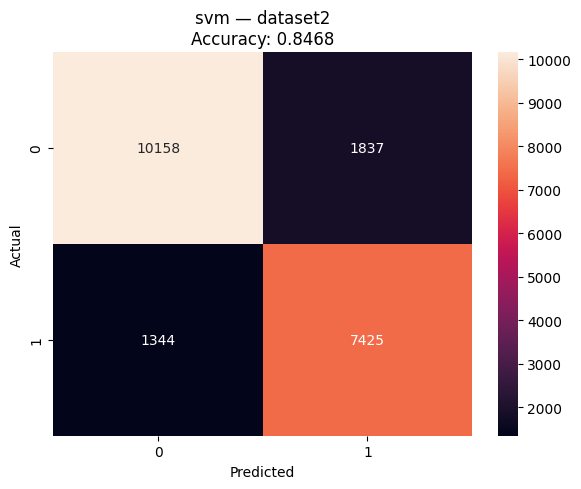

  Saved → dataset2/svm.pkl


,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forthe dual coordinate descent (if ``dual=True``). When ``dual=False`` theunderlying implementation of :class:`LinearSVC` is not random and``random_state`` has no effect on the results.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_iter max_iter: int, default=1000The maximum number of iterations to be run.",2000
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_

In [15]:
print("══ MODEL: SVM (LinearSVC) — Dataset 2 ══")

svm2 = LinearSVC(max_iter=2000, random_state=42, dual='auto', class_weight= 'balanced')
train_evaluate_save(svm2, 'svm', 'dataset2',
                     X_train2_scaled, y_train2, X_val2_scaled, y_val2)

9.1 SVM Variants Comparison

Subsample Setup

In [16]:
from sklearn.svm import SVC, NuSVC
from sklearn.linear_model import SGDClassifier

# ── Subsample Dataset 1 — chỉ dùng cho SVM variants (SVC/NuSVC chậm với data lớn) ──
SUBSAMPLE_SIZE = 30000

train1_sub, _ = train_test_split(
    train1,
    train_size=SUBSAMPLE_SIZE,
    random_state=42,
    stratify=train1['Label']
)

le_sub = LabelEncoder()
X_train1_sub        = train1_sub[FEATURE_COLS].values
y_train1_sub        = le_sub.fit_transform(train1_sub['Label'])
X_train1_sub_scaled = scaler1.transform(X_train1_sub)
LABEL_NAMES_SUB     = list(le_sub.classes_)

print(f"Dataset 1 subsample : {len(train1_sub):,} rows (từ {len(train1):,} rows gốc)")
print(f"Val set vẫn full    : {len(val1):,} rows")
print(f"\nLabel distribution (subsample):")
print(train1_sub['Label'].value_counts())

Dataset 1 subsample : 30,000 rows (từ 407,794 rows gốc)
Val set vẫn full    : 101,949 rows

Label distribution (subsample):
Label
benign        19969
defacement     4488
phishing       4430
malware        1113
Name: count, dtype: int64


SVC (kernel=rbf) — Dataset 1 (subsample 30K)

══ SVC (kernel=rbf) — Dataset 1 (subsample 30K) ══

  ── dataset1 ──
  Train time : 36.7s
  Accuracy   : 0.8097
  Confusion Matrix:
[[55184  4372   445  7861]
 [ 1653 12015    45  1536]
 [  237    78  3207   261]
 [ 1785   864   259 12147]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.94      0.81      0.87     67862
  defacement       0.69      0.79      0.74     15249
     malware       0.81      0.85      0.83      3783
    phishing       0.56      0.81      0.66     15055

    accuracy                           0.81    101949
   macro avg       0.75      0.81      0.77    101949
weighted avg       0.84      0.81      0.82    101949



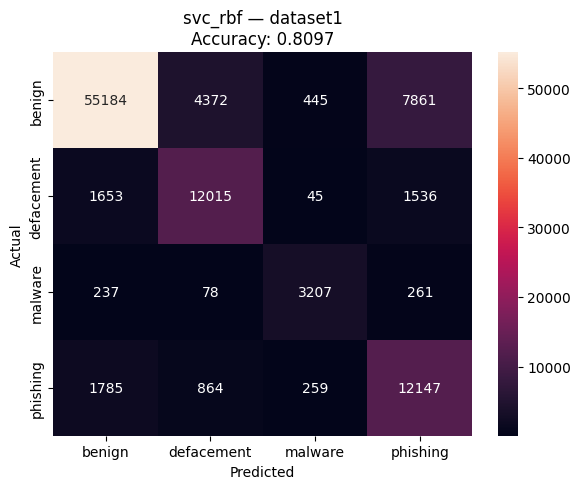

  Saved → dataset1/svc_rbf.pkl


,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200


In [17]:
from lightgbm import callback
print("══ SVC (kernel=rbf) — Dataset 1 (subsample 30K) ══")

svc_rbf1 = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42, class_weight='balanced')
train_evaluate_save(
    svc_rbf1, 'svc_rbf', 'dataset1',
    X_train1_sub_scaled, y_train1_sub,
    X_val1_scaled, y_val1,
    label_names=LABEL_NAMES_SUB
)

SVC (kernel=poly) — Dataset 1 (subsample 30K)

══ SVC (kernel=poly) — Dataset 1 (subsample 30K) ══

  ── dataset1 ──
  Train time : 35.1s
  Accuracy   : 0.8054
  Confusion Matrix:
[[58128  2631   273  6830]
 [ 3206  9784    17  2242]
 [  286    66  3150   281]
 [ 3382   428   198 11047]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.89      0.86      0.88     67862
  defacement       0.76      0.64      0.69     15249
     malware       0.87      0.83      0.85      3783
    phishing       0.54      0.73      0.62     15055

    accuracy                           0.81    101949
   macro avg       0.76      0.77      0.76    101949
weighted avg       0.82      0.81      0.81    101949



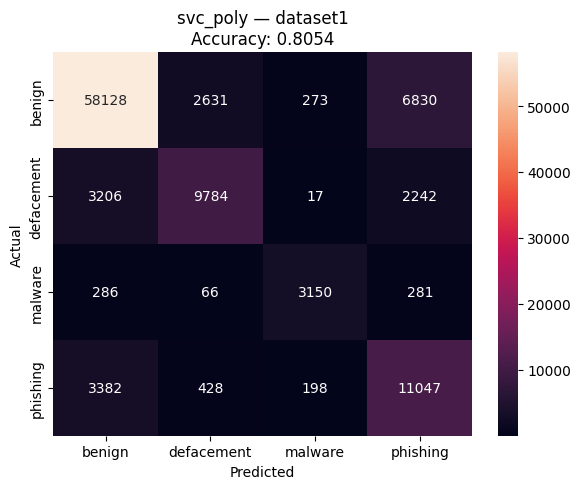

  Saved → dataset1/svc_poly.pkl


,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'poly'
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200


In [18]:
print("══ SVC (kernel=poly) — Dataset 1 (subsample 30K) ══")

svc_poly1 = SVC(kernel='poly', degree=3, C=1.0, random_state=42, class_weight='balanced')
train_evaluate_save(
    svc_poly1, 'svc_poly', 'dataset1',
    X_train1_sub_scaled, y_train1_sub,
    X_val1_scaled, y_val1,
    label_names=LABEL_NAMES_SUB
)

SGDClassifier — Dataset 1 (full)

══ SGDClassifier (loss=hinge) — Dataset 1 (full data) ══

  ── dataset1 ──
  Train time : 2.6s
  Accuracy   : 0.7828
  Confusion Matrix:
[[60847  2931   173  3911]
 [ 4157  9701     0  1391]
 [  582   119  2537   545]
 [ 7095  1007   234  6719]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.84      0.90      0.87     67862
  defacement       0.71      0.64      0.67     15249
     malware       0.86      0.67      0.75      3783
    phishing       0.53      0.45      0.49     15055

    accuracy                           0.78    101949
   macro avg       0.73      0.66      0.69    101949
weighted avg       0.77      0.78      0.78    101949



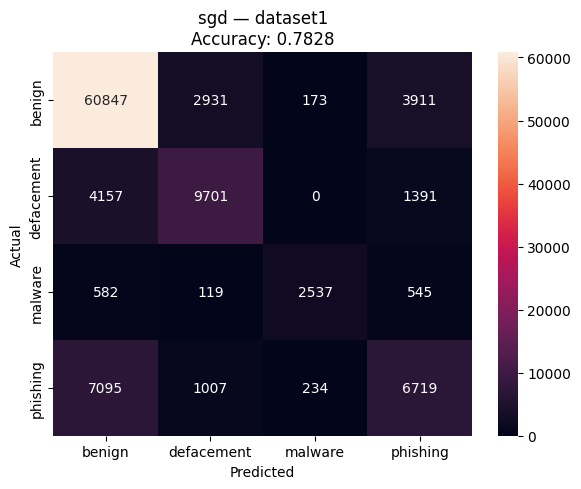

  Saved → dataset1/sgd.pkl


,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",-1
,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",42
,"class_weight class_weight: dict, {class_label: weight} or ""balanced"", default=NonePreset for the class_weight fit parameter.Weights associated with classes. If not given, all classesare supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, 

In [19]:
print("══ SGDClassifier (loss=hinge) — Dataset 1 (full data) ══")

sgd1 = SGDClassifier(
    loss='hinge',
    max_iter=1000,
    random_state=42,
    n_jobs=-1,
    class_weight= 'balanced'
)
train_evaluate_save(
    sgd1, 'sgd', 'dataset1',
    X_train1_scaled, y_train1,
    X_val1_scaled, y_val1,
    label_names=LABEL_NAMES_1
)

NuSVC — Dataset 1 (subsample 30K)

══ NuSVC — Dataset 1 (subsample 30K) ══

  ── dataset1 ──
  Train time : 34.4s
  Accuracy   : 0.8198
  Confusion Matrix:
[[60594  3055    12  4201]
 [ 3458 10885     2   904]
 [  569    64  2958   192]
 [ 5049   794    70  9142]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.87      0.89      0.88     67862
  defacement       0.74      0.71      0.72     15249
     malware       0.97      0.78      0.87      3783
    phishing       0.63      0.61      0.62     15055

    accuracy                           0.82    101949
   macro avg       0.80      0.75      0.77    101949
weighted avg       0.82      0.82      0.82    101949



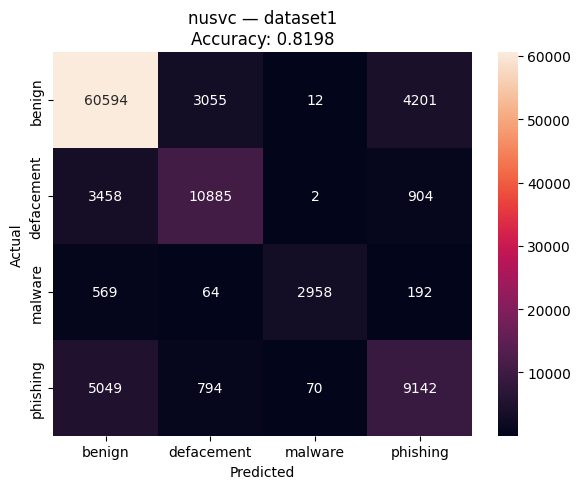

  Saved → dataset1/nusvc.pkl


,"nu nu: float, default=0.5An upper bound on the fraction of margin errors (see :ref:`User Guide<nu_svc>`) and a lower bound of the fraction of support vectors.Should be in the interval (0, 1].",0.03
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in version 1.11. Use `CalibratedClassifierCV(NuSVC(), ensemble=False)` instead of `NuSVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: {dict, 'balanced'}, default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one. The ""balanced"" mode uses the values of y to automaticallyadjust weights inversely proportional to class frequencies as``n_samples / (n_classes * np.bincount(y))``.",None


In [20]:
print("══ NuSVC — Dataset 1 (subsample 30K) ══")

# nu phải < tỉ lệ class nhỏ nhất × 2
# malware = 1113/30000 = 3.7% → nu an toàn < 0.037
nusvc1 = NuSVC(nu=0.03, kernel='rbf', random_state=42)
train_evaluate_save(
    nusvc1, 'nusvc', 'dataset1',
    X_train1_sub_scaled, y_train1_sub,
    X_val1_scaled, y_val1,
    label_names=LABEL_NAMES_SUB
)

SVC (kernel=rbf) — Dataset 2 (full)

══ SVC (kernel=rbf) — Dataset 2 (full) ══

  ── dataset2 ──
  Train time : 154.3s
  Accuracy   : 0.9321
  Confusion Matrix:
[[11420   575]
 [  835  7934]]

  Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.95      0.94     11995
           1       0.93      0.90      0.92      8769

    accuracy                           0.93     20764
   macro avg       0.93      0.93      0.93     20764
weighted avg       0.93      0.93      0.93     20764



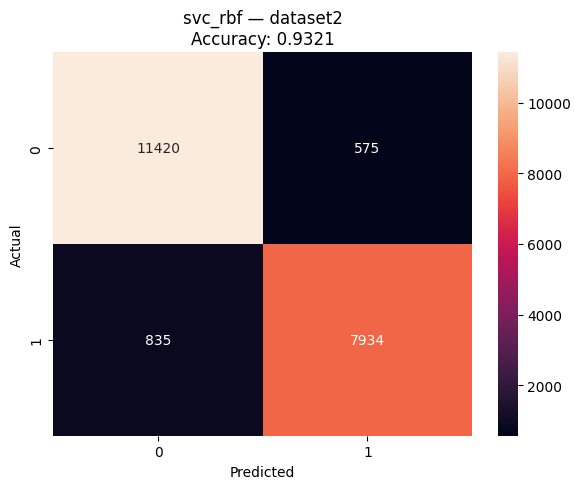

  Saved → dataset2/svc_rbf.pkl


,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200


In [21]:
print("══ SVC (kernel=rbf) — Dataset 2 (full) ══")

svc_rbf2 = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42, class_weight='balanced')
train_evaluate_save(
    svc_rbf2, 'svc_rbf', 'dataset2',
    X_train2_scaled, y_train2,
    X_val2_scaled, y_val2
)

SVC (kernel=poly) — Dataset 2 (full)

══ SVC (kernel=poly) — Dataset 2 (full) ══

  ── dataset2 ──
  Train time : 187.5s
  Accuracy   : 0.9198
  Confusion Matrix:
[[11432   563]
 [ 1102  7667]]

  Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.95      0.93     11995
           1       0.93      0.87      0.90      8769

    accuracy                           0.92     20764
   macro avg       0.92      0.91      0.92     20764
weighted avg       0.92      0.92      0.92     20764



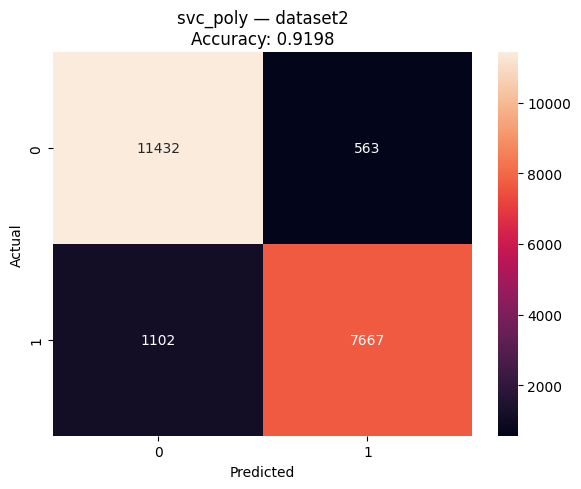

  Saved → dataset2/svc_poly.pkl


,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'poly'
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200


In [22]:
print("══ SVC (kernel=poly) — Dataset 2 (full) ══")

svc_poly2 = SVC(kernel='poly', degree=3, C=1.0, random_state=42, class_weight='balanced')
train_evaluate_save(
    svc_poly2, 'svc_poly', 'dataset2',
    X_train2_scaled, y_train2,
    X_val2_scaled, y_val2
)

SGDClassifier — Dataset 2 (full)

══ SGDClassifier (loss=hinge) — Dataset 2 (full) ══

  ── dataset2 ──
  Train time : 0.6s
  Accuracy   : 0.8577
  Confusion Matrix:
[[10308  1687]
 [ 1267  7502]]

  Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.86      0.87     11995
           1       0.82      0.86      0.84      8769

    accuracy                           0.86     20764
   macro avg       0.85      0.86      0.86     20764
weighted avg       0.86      0.86      0.86     20764



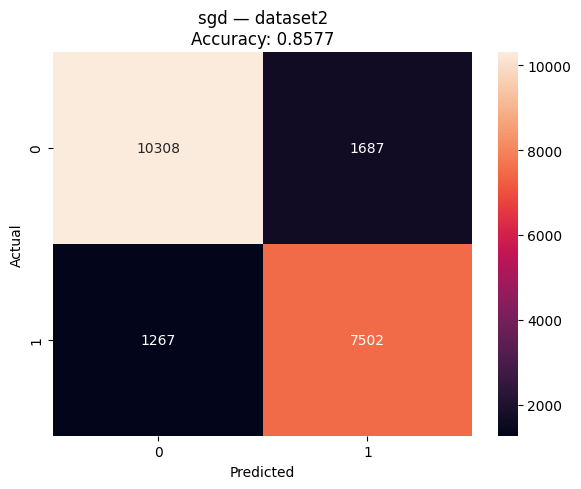

  Saved → dataset2/sgd.pkl


,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",-1
,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",42
,"class_weight class_weight: dict, {class_label: weight} or ""balanced"", default=NonePreset for the class_weight fit parameter.Weights associated with classes. If not given, all classesare supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, 

In [23]:
print("══ SGDClassifier (loss=hinge) — Dataset 2 (full) ══")

sgd2 = SGDClassifier(
    loss='hinge',
    max_iter=1000,
    random_state=42,
    n_jobs=-1,
    class_weight = 'balanced'
)
train_evaluate_save(
    sgd2, 'sgd', 'dataset2',
    X_train2_scaled, y_train2,
    X_val2_scaled, y_val2
)

NuSVC — Dataset 2 (full)

══ NuSVC — Dataset 2 (full) ══

  ── dataset2 ──


  Train time : 331.4s
  Accuracy   : 0.8892
  Confusion Matrix:
[[11165   830]
 [ 1470  7299]]

  Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.93      0.91     11995
           1       0.90      0.83      0.86      8769

    accuracy                           0.89     20764
   macro avg       0.89      0.88      0.89     20764
weighted avg       0.89      0.89      0.89     20764



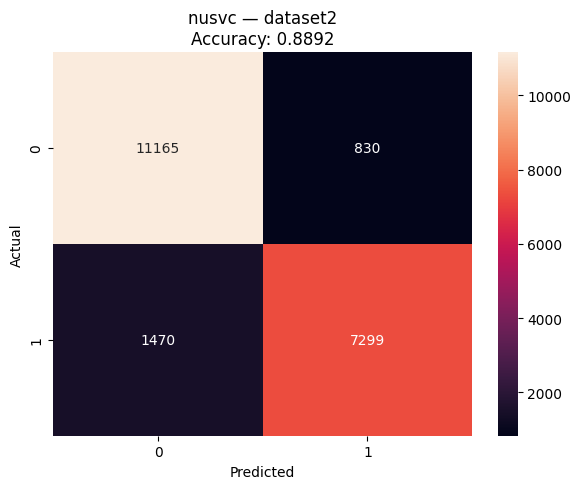

  Saved → dataset2/nusvc.pkl


,"nu nu: float, default=0.5An upper bound on the fraction of margin errors (see :ref:`User Guide<nu_svc>`) and a lower bound of the fraction of support vectors.Should be in the interval (0, 1].",0.4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in version 1.11. Use `CalibratedClassifierCV(NuSVC(), ensemble=False)` instead of `NuSVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: {dict, 'balanced'}, default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one. The ""balanced"" mode uses the values of y to automaticallyadjust weights inversely proportional to class frequencies as``n_samples / (n_classes * np.bincount(y))``.",None


In [24]:
print("══ NuSVC — Dataset 2 (full) ══")

# class nhỏ nhất = 42.2% → nu an toàn < 0.42
nusvc2 = NuSVC(nu=0.4, kernel='rbf', random_state=42)
train_evaluate_save(
    nusvc2, 'nusvc', 'dataset2',
    X_train2_scaled, y_train2,
    X_val2_scaled, y_val2
)

SVM Variants — Summary

In [25]:
svm_keys = [k for k in all_results if any(
    m in k for m in ['svm', 'svc_rbf', 'svc_poly', 'sgd', 'nusvc']
)]

svm_summary = pd.DataFrame([all_results[k] for k in svm_keys])
svm_summary = svm_summary.sort_values(
    ['dataset', 'accuracy'], ascending=[True, False]
).reset_index(drop=True)

print("── SVM Variants Comparison ──\n")
print(svm_summary.to_string(index=False))

svm_path = os.path.join(MODELS_DIR, 'svm_comparison.csv')
svm_summary.to_csv(svm_path, index=False)
print(f"\nExported → svm_comparison.csv")

── SVM Variants Comparison ──

 dataset    model  accuracy  train_time
dataset1    nusvc    0.8198        34.4
dataset1  svc_rbf    0.8097        36.7
dataset1 svc_poly    0.8054        35.1
dataset1      sgd    0.7828         2.6
dataset1      svm    0.7726       107.3
dataset2  svc_rbf    0.9321       154.3
dataset2 svc_poly    0.9198       187.5
dataset2    nusvc    0.8892       331.4
dataset2      sgd    0.8577         0.6
dataset2      svm    0.8468         2.6

Exported → svm_comparison.csv


9.2 Tree-based Variants

LightGBM

- Dataset 1

══ MODEL: LightGBM — Dataset 1 ══

  ── dataset1 ──
  Train time : 2.6s
  Accuracy   : 0.8987
  Confusion Matrix:
[[65396   894    15  1557]
 [ 2497 12002     6   744]
 [  297    27  3255   204]
 [ 3420   617    46 10972]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.91      0.96      0.94     67862
  defacement       0.89      0.79      0.83     15249
     malware       0.98      0.86      0.92      3783
    phishing       0.81      0.73      0.77     15055

    accuracy                           0.90    101949
   macro avg       0.90      0.83      0.86    101949
weighted avg       0.90      0.90      0.90    101949



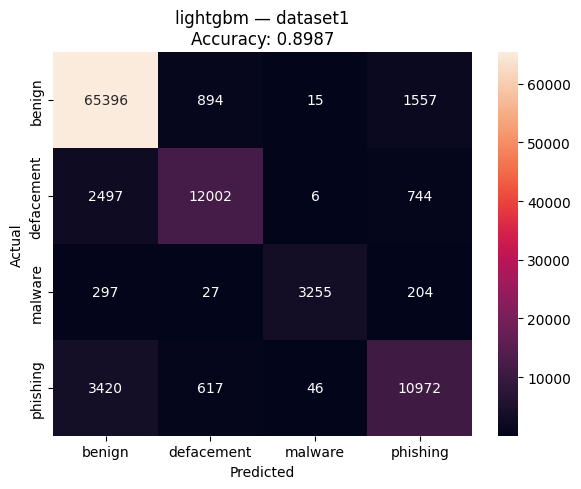

  Saved → dataset1/lightgbm.pkl


,objective,'multiclass'
,random_state,42
,n_jobs,-1
,num_class,4
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000


In [26]:
from lightgbm import LGBMClassifier

print("══ MODEL: LightGBM — Dataset 1 ══")

lgbm1 = LGBMClassifier(
    objective='multiclass',
    num_class=4,
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
train_evaluate_save(lgbm1, 'lightgbm', 'dataset1',
                     X_train1, y_train1, X_val1, y_val1,
                     label_names=LABEL_NAMES_1)

- Dataset 2


══ MODEL: LightGBM — Dataset 2 ══

  ── dataset2 ──
  Train time : 0.3s
  Accuracy   : 0.9540
  Confusion Matrix:
[[11626   369]
 [  586  8183]]

  Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.97      0.96     11995
           1       0.96      0.93      0.94      8769

    accuracy                           0.95     20764
   macro avg       0.95      0.95      0.95     20764
weighted avg       0.95      0.95      0.95     20764



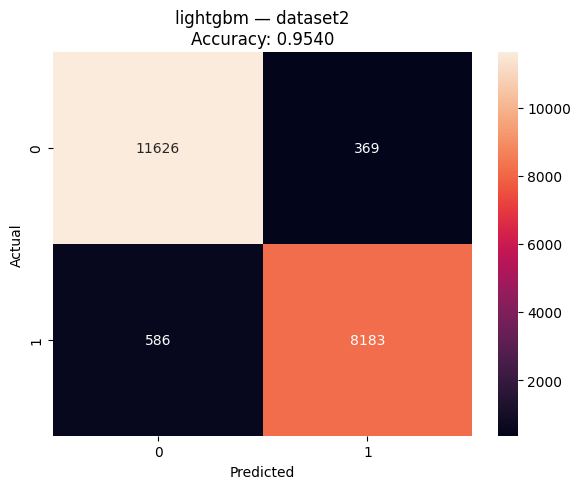

  Saved → dataset2/lightgbm.pkl


,random_state,42
,n_jobs,-1
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None


In [27]:
print("══ MODEL: LightGBM — Dataset 2 ══")

lgbm2 = LGBMClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
train_evaluate_save(lgbm2, 'lightgbm', 'dataset2',
                     X_train2, y_train2, X_val2, y_val2)

ExtraTreesClassifier


- Dataset 1

══ MODEL: ExtraTrees — Dataset 1 ══

  ── dataset1 ──
  Train time : 7.0s
  Accuracy   : 0.8568
  Confusion Matrix:
[[60060  2208    17  5577]
 [ 1927 11185     0  2137]
 [  250    53  3229   251]
 [ 1660   482    37 12876]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.94      0.89      0.91     67862
  defacement       0.80      0.73      0.77     15249
     malware       0.98      0.85      0.91      3783
    phishing       0.62      0.86      0.72     15055

    accuracy                           0.86    101949
   macro avg       0.84      0.83      0.83    101949
weighted avg       0.87      0.86      0.86    101949



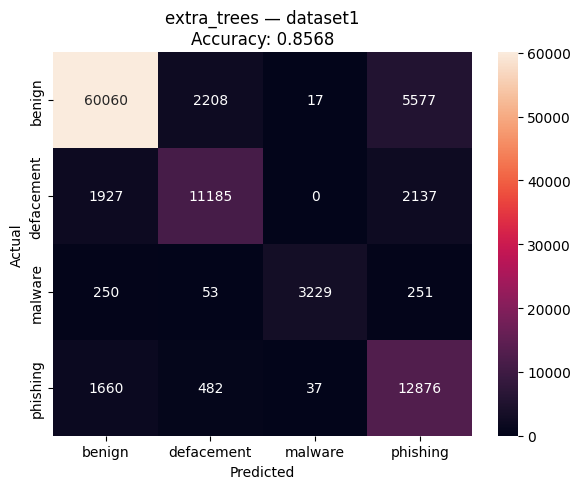

  Saved → dataset1/extra_trees.pkl


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls 3 sources of randomness:- the bootstrapping of the samples used when building trees (if ``bootstrap=True``)- the sampling of the features to consider when looking for the best split at each node (if ``max_features < n_features``)- the draw of the splits for each of the `max_features`See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when loo

In [28]:
from sklearn.ensemble import ExtraTreesClassifier

print("══ MODEL: ExtraTrees — Dataset 1 ══")

et1 = ExtraTreesClassifier(n_estimators=100, max_depth=20,
                             random_state=42, n_jobs=-1, class_weight='balanced')
train_evaluate_save(et1, 'extra_trees', 'dataset1',
                     X_train1, y_train1, X_val1, y_val1,
                     label_names=LABEL_NAMES_1)

- Dataset 2

══ MODEL: ExtraTrees — Dataset 2 ══

  ── dataset2 ──
  Train time : 0.7s
  Accuracy   : 0.9470
  Confusion Matrix:
[[11648   347]
 [  754  8015]]

  Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.97      0.95     11995
           1       0.96      0.91      0.94      8769

    accuracy                           0.95     20764
   macro avg       0.95      0.94      0.95     20764
weighted avg       0.95      0.95      0.95     20764



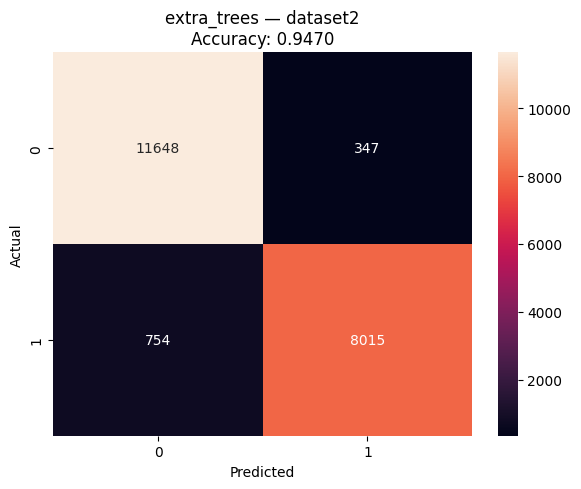

  Saved → dataset2/extra_trees.pkl


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls 3 sources of randomness:- the bootstrapping of the samples used when building trees (if ``bootstrap=True``)- the sampling of the features to consider when looking for the best split at each node (if ``max_features < n_features``)- the draw of the splits for each of the `max_features`See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when loo

In [29]:
print("══ MODEL: ExtraTrees — Dataset 2 ══")

et2 = ExtraTreesClassifier(n_estimators=100, max_depth=20,
                             random_state=42, n_jobs=-1, class_weight='balanced')
train_evaluate_save(et2, 'extra_trees', 'dataset2',
                     X_train2, y_train2, X_val2, y_val2)

BaggingClassifier


- Dataset 1

══ MODEL: Bagging — Dataset 1 ══

  ── dataset1 ──
  Train time : 54.9s
  Accuracy   : 0.9160
  Confusion Matrix:
[[65644   717    10  1491]
 [ 1774 12888     0   587]
 [  277    38  3272   196]
 [ 2887   540    49 11579]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.93      0.97      0.95     67862
  defacement       0.91      0.85      0.88     15249
     malware       0.98      0.86      0.92      3783
    phishing       0.84      0.77      0.80     15055

    accuracy                           0.92    101949
   macro avg       0.91      0.86      0.89    101949
weighted avg       0.91      0.92      0.91    101949



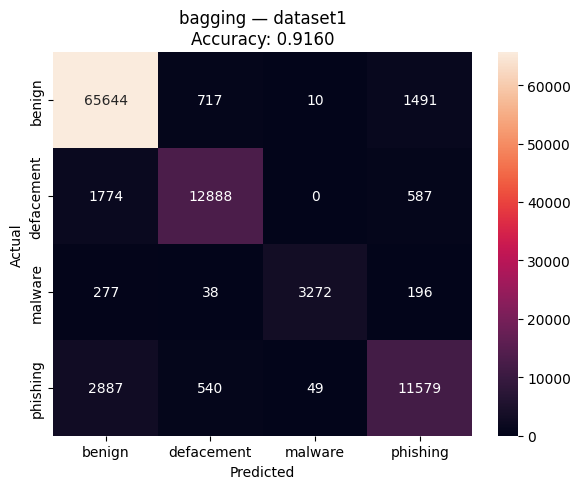

  Saved → dataset1/bagging.pkl


,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeClassifier`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...ndom_state=42)
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",100
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",None
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",1.0
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",True
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",False
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",False
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary <warm_start>`... versionadded:: 0.17 *warm_start* constructor parameter.",False
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


In [30]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

print("══ MODEL: Bagging — Dataset 1 ══")

bag1 = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=20, random_state=42),
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
train_evaluate_save(bag1, 'bagging', 'dataset1',
                     X_train1, y_train1, X_val1, y_val1,
                     label_names=LABEL_NAMES_1)

- Dataset 2

══ MODEL: Bagging — Dataset 2 ══

  ── dataset2 ──
  Train time : 7.7s
  Accuracy   : 0.9613
  Confusion Matrix:
[[11691   304]
 [  500  8269]]

  Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.97      0.97     11995
           1       0.96      0.94      0.95      8769

    accuracy                           0.96     20764
   macro avg       0.96      0.96      0.96     20764
weighted avg       0.96      0.96      0.96     20764



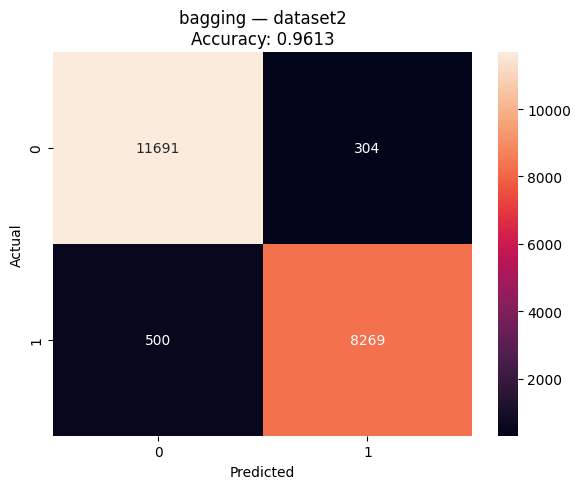

  Saved → dataset2/bagging.pkl


,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeClassifier`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...ndom_state=42)
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",100
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",None
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",1.0
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",True
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",False
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",False
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary <warm_start>`... versionadded:: 0.17 *warm_start* constructor parameter.",False
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


In [31]:
print("══ MODEL: Bagging — Dataset 2 ══")

bag2 = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=20, random_state=42),
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
train_evaluate_save(bag2, 'bagging', 'dataset2',
                     X_train2, y_train2, X_val2, y_val2)

AdaBoostClassifier


- Dataset 1

══ MODEL: AdaBoost — Dataset 1 ══

  ── dataset1 ──
  Train time : 36.3s
  Accuracy   : 0.7808
  Confusion Matrix:
[[66379   443    57   983]
 [10090  4947     0   212]
 [  712    15  2424   632]
 [ 8896    52   251  5856]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.77      0.98      0.86     67862
  defacement       0.91      0.32      0.48     15249
     malware       0.89      0.64      0.74      3783
    phishing       0.76      0.39      0.52     15055

    accuracy                           0.78    101949
   macro avg       0.83      0.58      0.65    101949
weighted avg       0.79      0.78      0.75    101949



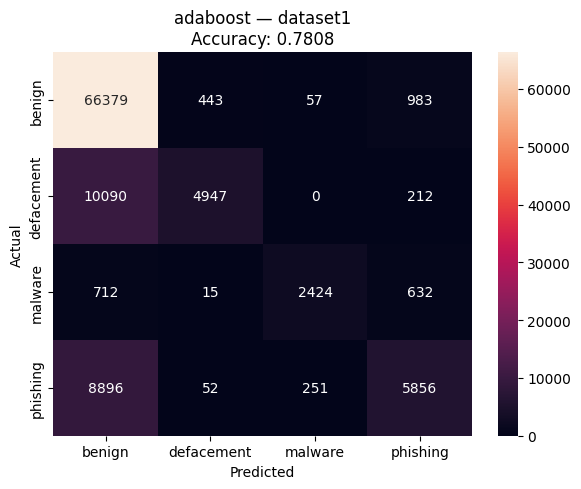

  Saved → dataset1/adaboost.pkl


,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",100
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](4,)","[0,1,2,3]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](100,)","[0.33,0.52,0.58,...,0.74,0.73,0.73]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](100,)","[1.79,1. ,0.76,...,0.07,0.09,0.11]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=1608637542), DecisionTreeC...te=1273642419), DecisionTreeC...te=1935803228), DecisionTreeC...ate=787846414), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](32,)","[0.01,0. ,0.22,...,0. ,0. ,0. ]"


In [32]:
from sklearn.ensemble import AdaBoostClassifier

print("══ MODEL: AdaBoost — Dataset 1 ══")

ada1 = AdaBoostClassifier(
    n_estimators=100,
    random_state=42
)
train_evaluate_save(ada1, 'adaboost', 'dataset1',
                     X_train1, y_train1, X_val1, y_val1,
                     label_names=LABEL_NAMES_1)

- Dataset 2

══ MODEL: AdaBoost — Dataset 2 ══

  ── dataset2 ──
  Train time : 6.5s
  Accuracy   : 0.8610
  Confusion Matrix:
[[10837  1158]
 [ 1729  7040]]

  Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.90      0.88     11995
           1       0.86      0.80      0.83      8769

    accuracy                           0.86     20764
   macro avg       0.86      0.85      0.86     20764
weighted avg       0.86      0.86      0.86     20764



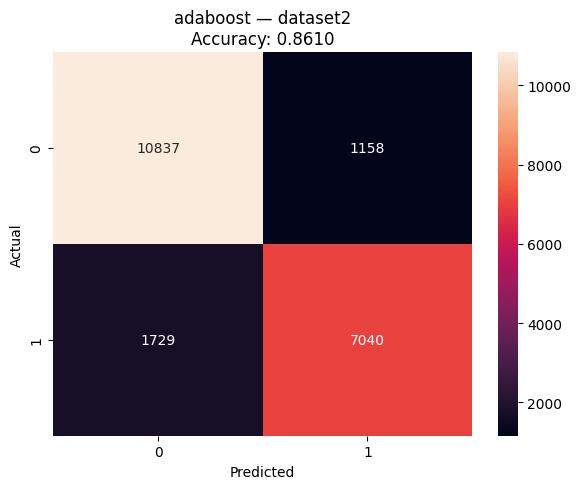

  Saved → dataset2/adaboost.pkl


,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",100
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](100,)","[0.28,0.3 ,0.36,...,0.45,0.45,0.47]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](100,)","[0.96,0.84,0.58,...,0.2 ,0.21,0.1 ]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=1608637542), DecisionTreeC...te=1273642419), DecisionTreeC...te=1935803228), DecisionTreeC...ate=787846414), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](32,)","[0.06,0.02,0.18,...,0.06,0.09,0. ]"


In [33]:
print("══ MODEL: AdaBoost — Dataset 2 ══")

ada2 = AdaBoostClassifier(
    n_estimators=100,
    random_state=42
)
train_evaluate_save(ada2, 'adaboost', 'dataset2',
                     X_train2, y_train2, X_val2, y_val2)

GradientBoostingClassifier

- Dataset 1

══ MODEL: GradientBoosting — Dataset 1 ══

  ── dataset1 ──
  Train time : 447.6s
  Accuracy   : 0.8616
  Confusion Matrix:
[[65118  1123    12  1609]
 [ 4062 10279     0   908]
 [  500    57  3003   223]
 [ 4870   660    81  9444]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.87      0.96      0.91     67862
  defacement       0.85      0.67      0.75     15249
     malware       0.97      0.79      0.87      3783
    phishing       0.78      0.63      0.69     15055

    accuracy                           0.86    101949
   macro avg       0.87      0.76      0.81    101949
weighted avg       0.86      0.86      0.86    101949



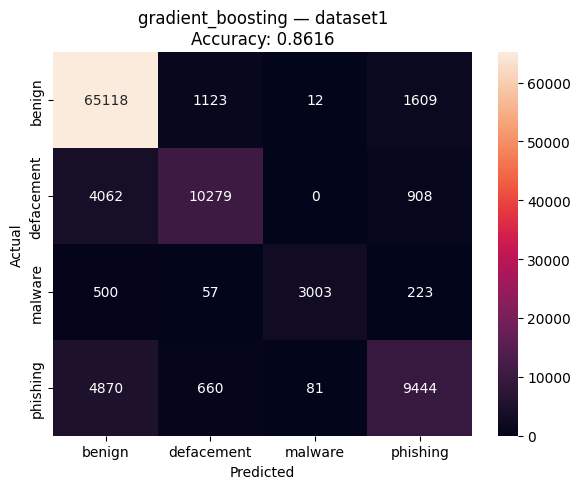

  Saved → dataset1/gradient_boosting.pkl


,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [34]:
from sklearn.ensemble import GradientBoostingClassifier

print("══ MODEL: GradientBoosting — Dataset 1 ══")

gb1 = GradientBoostingClassifier(
    n_estimators=100,
    random_state=42
)
train_evaluate_save(gb1, 'gradient_boosting', 'dataset1',
                     X_train1, y_train1, X_val1, y_val1,
                     label_names=LABEL_NAMES_1)

- Dataset 2

══ MODEL: GradientBoosting — Dataset 2 ══

  ── dataset2 ──
  Train time : 24.6s
  Accuracy   : 0.9200
  Confusion Matrix:
[[11426   569]
 [ 1093  7676]]

  Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.95      0.93     11995
           1       0.93      0.88      0.90      8769

    accuracy                           0.92     20764
   macro avg       0.92      0.91      0.92     20764
weighted avg       0.92      0.92      0.92     20764



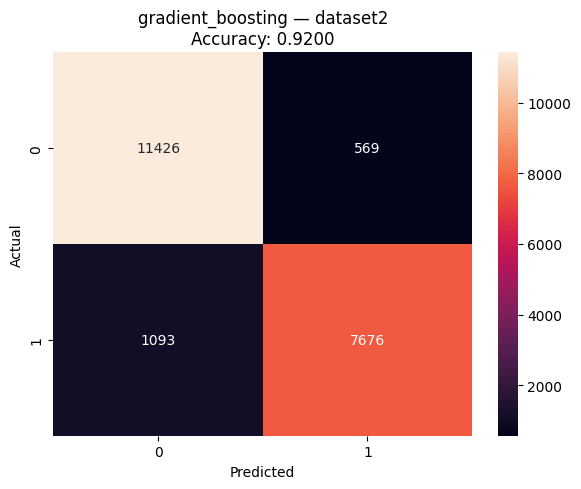

  Saved → dataset2/gradient_boosting.pkl


,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [35]:
print("══ MODEL: GradientBoosting — Dataset 2 ══")

gb2 = GradientBoostingClassifier(
    n_estimators=100,
    random_state=42
)
train_evaluate_save(gb2, 'gradient_boosting', 'dataset2',
                     X_train2, y_train2, X_val2, y_val2)

10. Random Forest


- Dataset 1

══ MODEL: Random Forest — Dataset 1 ══

  ── dataset1 ──
  Train time : 12.5s
  Accuracy   : 0.9109
  Confusion Matrix:
[[65908   572     2  1380]
 [ 2203 12336     0   710]
 [  350    26  3216   191]
 [ 3130   490    28 11407]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.92      0.97      0.95     67862
  defacement       0.92      0.81      0.86     15249
     malware       0.99      0.85      0.92      3783
    phishing       0.83      0.76      0.79     15055

    accuracy                           0.91    101949
   macro avg       0.92      0.85      0.88    101949
weighted avg       0.91      0.91      0.91    101949



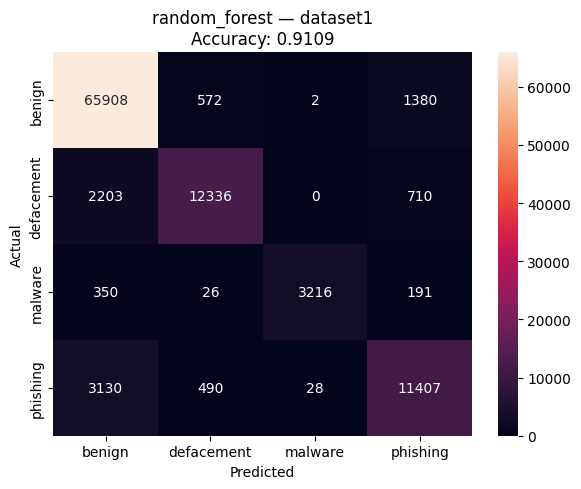

  Saved → dataset1/random_forest.pkl


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total n

In [36]:
from sklearn.ensemble import RandomForestClassifier

print("══ MODEL: Random Forest — Dataset 1 ══")

rf1 = RandomForestClassifier(n_estimators=100, max_depth=20,
                               random_state=42, n_jobs=-1)
train_evaluate_save(rf1, 'random_forest', 'dataset1',
                     X_train1, y_train1, X_val1, y_val1,
                     label_names=LABEL_NAMES_1)

- Dataset 2

══ MODEL: Random Forest — Dataset 2 ══

  ── dataset2 ──
  Train time : 1.7s
  Accuracy   : 0.9630
  Confusion Matrix:
[[11721   274]
 [  495  8274]]

  Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97     11995
           1       0.97      0.94      0.96      8769

    accuracy                           0.96     20764
   macro avg       0.96      0.96      0.96     20764
weighted avg       0.96      0.96      0.96     20764



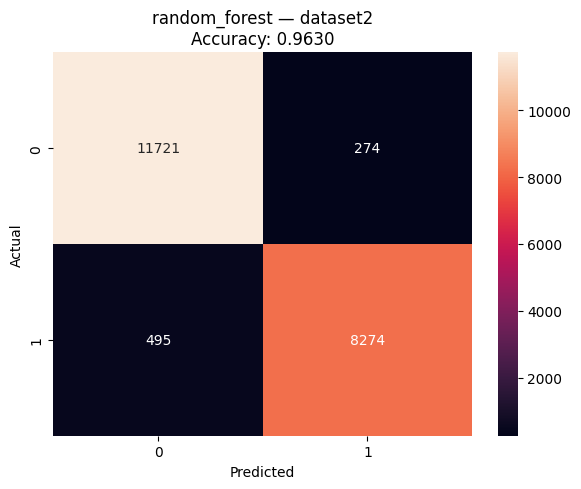

  Saved → dataset2/random_forest.pkl


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total n

In [37]:
print("══ MODEL: Random Forest — Dataset 2 ══")

rf2 = RandomForestClassifier(n_estimators=100, max_depth=20,
                               random_state=42, n_jobs=-1)
train_evaluate_save(rf2, 'random_forest', 'dataset2',
                     X_train2, y_train2, X_val2, y_val2)

11. XGBoost

- Dataset 1

══ MODEL: XGBoost — Dataset 1 ══

  ── dataset1 ──
  Train time : 6.7s
  Accuracy   : 0.9009
  Confusion Matrix:
[[65534   827    10  1491]
 [ 2505 11956     1   787]
 [  318    25  3243   197]
 [ 3281   624    34 11116]]

  Classification Report:
              precision    recall  f1-score   support

      benign       0.91      0.97      0.94     67862
  defacement       0.89      0.78      0.83     15249
     malware       0.99      0.86      0.92      3783
    phishing       0.82      0.74      0.78     15055

    accuracy                           0.90    101949
   macro avg       0.90      0.84      0.87    101949
weighted avg       0.90      0.90      0.90    101949



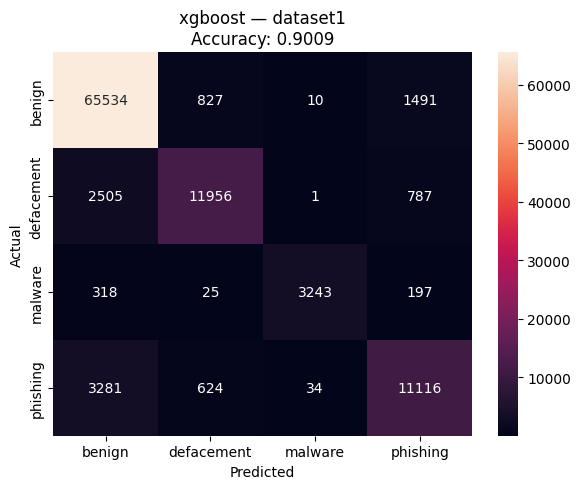

  Saved → dataset1/xgboost.pkl


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import lo

In [38]:
from xgboost import XGBClassifier

print("══ MODEL: XGBoost — Dataset 1 ══")

xgb1 = XGBClassifier(n_estimators=100, max_depth=8, learning_rate=0.1,
                       random_state=42, eval_metric='mlogloss',
                       n_jobs=-1, verbosity=0)
train_evaluate_save(xgb1, 'xgboost', 'dataset1',
                     X_train1, y_train1, X_val1, y_val1,
                     label_names=LABEL_NAMES_1)

- Dataset 2

══ MODEL: XGBoost — Dataset 2 ══

  ── dataset2 ──
  Train time : 0.6s
  Accuracy   : 0.9590
  Confusion Matrix:
[[11650   345]
 [  506  8263]]

  Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.97      0.96     11995
           1       0.96      0.94      0.95      8769

    accuracy                           0.96     20764
   macro avg       0.96      0.96      0.96     20764
weighted avg       0.96      0.96      0.96     20764



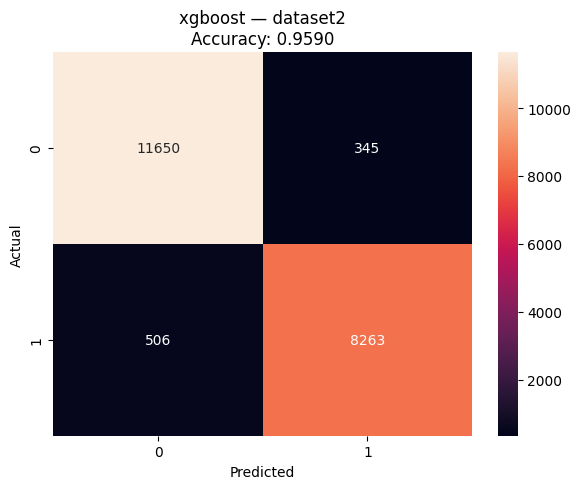

  Saved → dataset2/xgboost.pkl


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [39]:
print("══ MODEL: XGBoost — Dataset 2 ══")

xgb2 = XGBClassifier(n_estimators=100, max_depth=8, learning_rate=0.1,
                       random_state=42, eval_metric='logloss',
                       n_jobs=-1, verbosity=0)
train_evaluate_save(xgb2, 'xgboost', 'dataset2',
                     X_train2, y_train2, X_val2, y_val2)

12. Comparison Summary

In [40]:
summary = pd.DataFrame(all_results.values())
summary = summary.sort_values(['dataset', 'accuracy'], ascending=[True, False])

print("── So sánh tất cả model × dataset ──\n")
print(summary.to_string(index=False))

summary_path = os.path.join(MODELS_DIR, 'model_comparison.csv')
summary.to_csv(summary_path, index=False)
print(f"\nExported → {os.path.basename(summary_path)}")

── So sánh tất cả model × dataset ──

 dataset                             model  accuracy  train_time
dataset1                           bagging    0.9160        54.9
dataset1                     random_forest    0.9109        12.5
dataset1                               knn    0.9038         0.1
dataset1                           xgboost    0.9009         6.7
dataset1                          lightgbm    0.8987         2.6
dataset1                     decision_tree    0.8794         6.6
dataset1                 gradient_boosting    0.8616       447.6
dataset1                       extra_trees    0.8568         7.0
dataset1                             nusvc    0.8198        34.4
dataset1                           svc_rbf    0.8097        36.7
dataset1                          svc_poly    0.8054        35.1
dataset1                               sgd    0.7828         2.6
dataset1                          adaboost    0.7808        36.3
dataset1                               svm    0.7726

13. Error Analysis (Dataset 1)

13.1 Load predictions từ toàn bộ model đã train

In [41]:
# Load lại toàn bộ model Dataset 1 đã train (.pkl), predict trên val set
# để có ma trận dự đoán của tất cả model — phục vụ phân tích lỗi tổng hợp

DS1_SCALED_MODELS = {
    'knn', 'svm', 'svc_rbf', 'svc_poly', 'nusvc', 'sgd',
    'logistic_regression', 'logistic_regression_custom_manual'
}

ds1_model_keys = sorted([info['model'] for k, info in all_results.items()
                          if info['dataset'] == 'dataset1'])

predictions_ds1 = {}
for model_key in ds1_model_keys:
    model_path = os.path.join(MODELS_DIR, 'dataset1', f'{model_key}.pkl')
    model = joblib.load(model_path)
    X_input = X_val1_scaled if model_key in DS1_SCALED_MODELS else X_val1
    predictions_ds1[model_key] = model.predict(X_input)

print(f"Đã load predictions cho {len(predictions_ds1)} model Dataset 1:")
print(list(predictions_ds1.keys()))

Đã load predictions cho 16 model Dataset 1:
['adaboost', 'bagging', 'decision_tree', 'extra_trees', 'gradient_boosting', 'knn', 'lightgbm', 'logistic_regression', 'logistic_regression_custom_manual', 'nusvc', 'random_forest', 'sgd', 'svc_poly', 'svc_rbf', 'svm', 'xgboost']


13.2 Xác định "hard cases" - sample bị nhiều model cùng đoán sai

In [42]:
# Với mỗi sample trong val set, đếm xem có bao nhiêu model (trong tổng số N model) đoán sai
pred_matrix = np.column_stack(list(predictions_ds1.values()))  # shape (n_val, n_models)
model_names_order = list(predictions_ds1.keys())
n_models_total = len(model_names_order)

is_wrong = pred_matrix != y_val1[:, None]
n_wrong_per_sample = is_wrong.sum(axis=1)

val1_analysis = val1.copy()
val1_analysis['n_models_wrong'] = n_wrong_per_sample
val1_analysis['n_models_total'] = n_models_total
val1_analysis['pct_models_wrong'] = (n_wrong_per_sample / n_models_total * 100).round(1)

print("── Phân phối số model đoán sai trên mỗi sample (Dataset 1 val set) ──")
print(val1_analysis['n_models_wrong'].value_counts().sort_index())

# Hard cases: bị từ 70% model trở lên đoán sai
threshold = 0.7
hard_cases = val1_analysis[val1_analysis['n_models_wrong'] >= n_models_total * threshold]
print(f"\n{len(hard_cases)} sample bị >= {int(threshold*100)}% model ({int(n_models_total*threshold)}/{n_models_total}) đoán sai")
print(f"Tỉ lệ trên tổng val set: {len(hard_cases)/len(val1_analysis)*100:.2f}%")

print("\nPhân bố label của các hard cases:")
print(hard_cases['Label'].value_counts())

── Phân phối số model đoán sai trên mỗi sample (Dataset 1 val set) ──
n_models_wrong
0     46200
1     17449
2      7103
3      5346
4      4678
5      3089
6      2956
7      2340
8      1790
9      1529
10     1236
11     1111
12     1069
13     1167
14     1303
15     1627
16     1956
Name: count, dtype: int64

7122 sample bị >= 70% model (11/16) đoán sai
Tỉ lệ trên tổng val set: 6.99%

Phân bố label của các hard cases:
Label
defacement    2596
phishing      2530
benign        1464
malware        532
Name: count, dtype: int64


13.3 Confusion pairs phổ biến nhất (tổng hợp toàn bộ model)

── Top 10 confusion pairs (tổng hợp qua toàn bộ 16 model, Dataset 1) ──
true_label pred_label  count
    benign   phishing  69276
  phishing     benign  66357
defacement     benign  51673
    benign defacement  35744
defacement   phishing  18470
  phishing defacement  11120
   malware     benign   6335
   malware   phishing   4242
  phishing    malware   3307
    benign    malware   2907


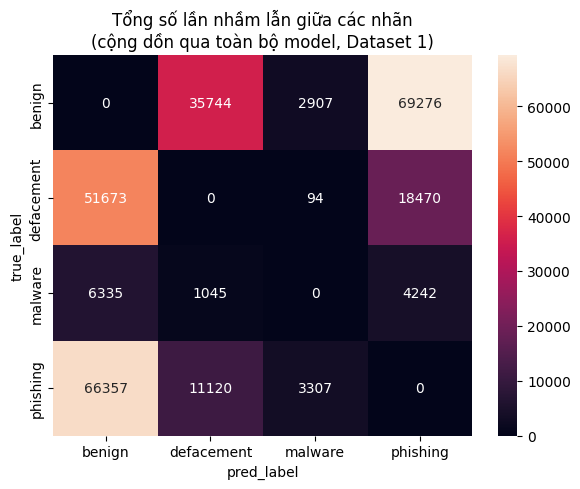

In [43]:
from collections import Counter

# Đếm tần suất các cặp (nhãn thật, nhãn đoán) bị sai, tổng hợp qua TẤT CẢ model
pair_counter = Counter()
for model_key, y_pred in predictions_ds1.items():
    wrong_mask = y_pred != y_val1
    true_wrong = y_val1[wrong_mask]
    pred_wrong = y_pred[wrong_mask]
    for t, p in zip(true_wrong, pred_wrong):
        pair_counter[(LABEL_NAMES_1[t], LABEL_NAMES_1[p])] += 1

pair_df = pd.DataFrame(
    [(t, p, c) for (t, p), c in pair_counter.items()],
    columns=['true_label', 'pred_label', 'count']
).sort_values('count', ascending=False).reset_index(drop=True)

print("── Top 10 confusion pairs (tổng hợp qua toàn bộ 16 model, Dataset 1) ──")
print(pair_df.head(10).to_string(index=False))

# Heatmap trực quan các cặp nhầm lẫn
pivot = pair_df.pivot_table(index='true_label', columns='pred_label', values='count', fill_value=0)
plt.figure(figsize=(6, 5))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='rocket')
plt.title('Tổng số lần nhầm lẫn giữa các nhãn\n(cộng dồn qua toàn bộ model, Dataset 1)')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '..', 'error_analysis_confusion_pairs.png'), dpi=150)
plt.show()

13.4 So sánh phân phối feature: đúng vs sai (theo Mutual Information ranking)

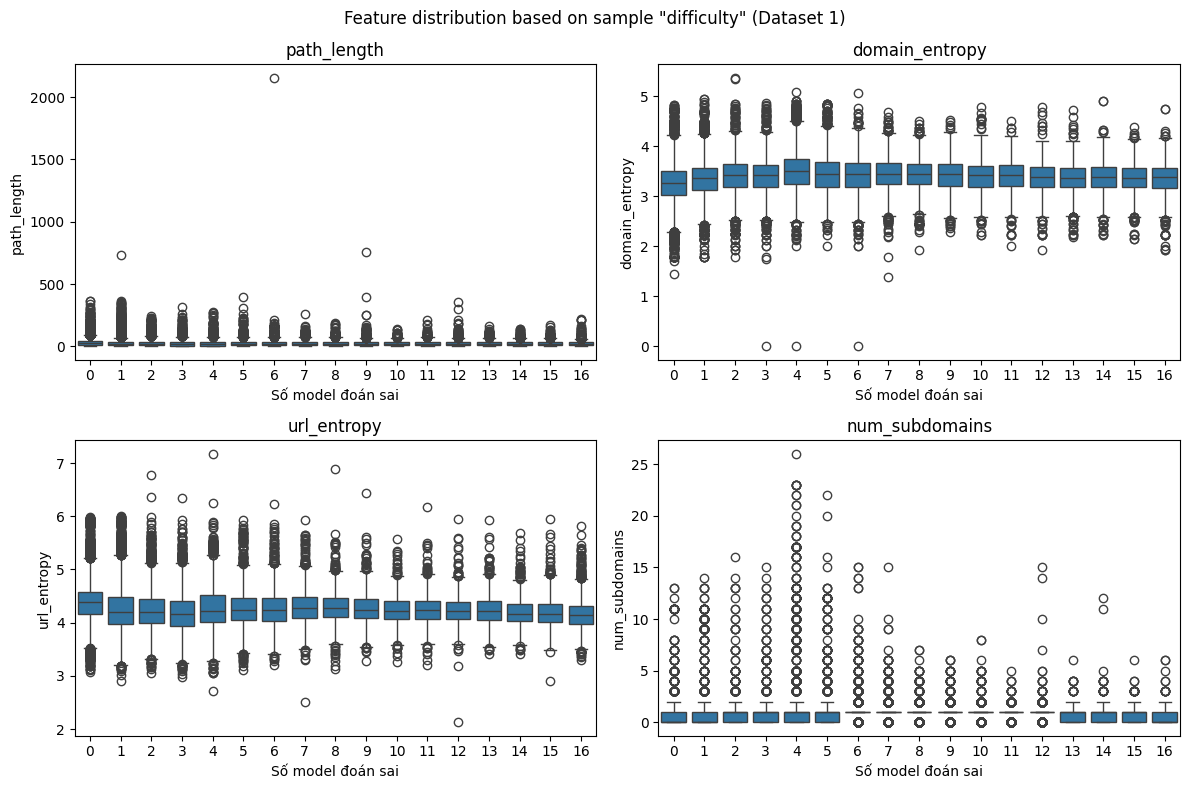

In [44]:
# Dùng lại top feature quan trọng nhất theo Mutual Information đã tính ở eda_features.ipynb
top_features = ['path_length', 'domain_entropy', 'url_entropy', 'num_subdomains']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feat in zip(axes.flatten(), top_features):
    sns.boxplot(data=val1_analysis, x='n_models_wrong', y=feat, ax=ax)
    ax.set_title(feat)
    ax.set_xlabel('Số model đoán sai')

plt.suptitle('Feature distribution based on sample "difficulty" (Dataset 1)')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, '..', 'error_analysis_feature_distribution.png'), dpi=150)
plt.show()

13.5 URL thực tế của các hard cases

In [45]:
# In ra URL thực tế của 20 hard cases bị nhiều model đoán sai nhất — để xem thủ công
print("── 20 hard cases tiêu biểu (Dataset 1) ──\n")
top_hard = val1_analysis.sort_values('n_models_wrong', ascending=False).head(20)
for _, row in top_hard.iterrows():
    print(f"[{row['n_models_wrong']}/{row['n_models_total']} model sai] True={row['Label']:12s} | {row['URL'][:90]}")

# Export toàn bộ hard cases ra CSV để phân tích/nộp báo cáo
hard_cases_export = hard_cases[['URL', 'Label', 'n_models_wrong', 'n_models_total', 'pct_models_wrong'] + FEATURE_COLS]
export_path = os.path.join(MODELS_DIR, 'hard_cases_dataset1.csv')
hard_cases_export.to_csv(export_path, index=False)
print(f"\nĐã export {len(hard_cases_export)} hard cases → {os.path.basename(export_path)}")

── 20 hard cases tiêu biểu (Dataset 1) ──

[16/16 model sai] True=phishing     | http://palletsolutions.ca/basic/bankofamerica
[16/16 model sai] True=phishing     | http://tud.at/programm/apache-ssl-win32-howto.php3
[16/16 model sai] True=phishing     | http://jodies.de/ipcalc
[16/16 model sai] True=phishing     | http://w3.org/MarkUp/html-spec/L2Pindex.html
[16/16 model sai] True=phishing     | http://detrave.net/nblume/hcadmintool/
[16/16 model sai] True=malware      | http://shahtoba.faqserv.com/shaht64.exe
[16/16 model sai] True=malware      | http://ti0tvpvn5wbe2jy9.bid
[16/16 model sai] True=phishing     | http://pagesperso-orange.fr/bernard.lupin/english/index.htm
[16/16 model sai] True=phishing     | http://xn--ugbd1cbxo23egh.com/citrixsh/741aab48efe6941bf0620552b7fb6753/sf8743rg387efg9823
[16/16 model sai] True=malware      | http://admin.mymagno.com/0G6r8t4vWcy-tusBXfVBwJH6BEvyll8DfUfQKSkIvBAKIOJmwEEvu05sIjLNu6XeN
[16/16 model sai] True=benign       | http://support.microsoft